<a href="https://colab.research.google.com/github/EBY-analytics/python-practice/blob/main/yalcin_assign_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
print("Hello DSP 556")

Hello DSP 556


**Part 1: Linear Regression**

In [2]:
from google.colab import files

uploaded = files.upload()

Saving bikes.csv to bikes.csv


In [3]:
import pandas as pd
import numpy as np

In [4]:
bikes = pd.read_csv("bikes.csv")

In [5]:
bikes.head()

,date,season,year,month,day_of_week,weekend,holiday,temp_actual,temp_feel,humidity,windspeed,weather_cat,rides
0,2011-01-01,winter,2011,Jan,Sat,True,no,57.399525,64.72625,80.5833,10.749882,categ2,654
1,2011-01-03,winter,2011,Jan,Mon,False,no,46.491663,49.04645,43.7273,16.636703,categ1,1229
2,2011-01-04,winter,2011,Jan,Tue,False,no,46.760000,51.09098,59.0435,10.739832,categ1,1454
3,2011-01-05,winter,2011,Jan,Wed,False,no,48.749427,52.63430,43.6957,12.522300,categ1,1518
4,2011-01-07,winter,2011,Jan,Fri,False,no,46.503324,50.79551,49.8696,11.304642,categ2,1362


In [6]:
bikes.shape

(500, 13)

In [7]:
bikes.dtypes

,0
date,object
season,object
year,int64
month,object
day_of_week,object
weekend,bool
holiday,object
temp_actual,float64
temp_feel,float64
humidity,float64


Data Types:

1.   Numerical Variables

*   year
*   temp_actual
*   temp_feel
*   humidity
*   windspeed
*   rides

2.   Categorical Variables

*   date
*   season
*   month
*   day_of_week
*   holiday
*   weekend
*   weather_cat

3.   Ordinal Variables

*   weather_cat (may be considered ordinal if its categories represent increasing weather severity)

In [8]:
from sklearn.model_selection import train_test_split

In [9]:
predictors = ['temp_feel', 'windspeed', 'weekend']

X = bikes[predictors]
y = bikes['rides']

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=1
)

In [11]:
X_train.shape

(400, 3)

In [12]:
X_test.shape

(100, 3)

Interpretation: Training and Test Split

The dataset contains 500 observations. An 80/20 split was used to create training and test datasets.

*   Training set: 400 observations (80%)
*   Test set: 100 observations (20%)

The training set will be used to fit the regression model, while the test set will be used to evaluate model performance on unseen data.

In [13]:
from sklearn.linear_model import LinearRegression

In [14]:
model = LinearRegression()

In [15]:
model.fit(X_train, y_train)

LinearRegression()

In [16]:
list(zip(predictors, model.coef_))

[('temp_feel', np.float64(82.06801696508325)),
 ('windspeed', np.float64(-30.375717181369268)),
 ('weekend', np.float64(-683.4340791178067))]

Interpretation: Model Coefficient

The coefficient for temp_feel is 82.07. Holding all other variables constant, a one-unit increase in perceived temperature is associated with an increase of approximately 82 rides.

The coefficient for windspeed is -30.38. Holding all other variables constant, a one-unit increase in windspeed is associated with a decrease of approximately 30 rides.

The coefficient for weekend is -683.43. Holding all other variables constant, weekend days are predicted to have approximately 683 fewer rides than non-weekend days.

In [17]:
y_pred = model.predict(X_train)

In [18]:
import sklearn.metrics as skm

In [19]:
r2_score = skm.r2_score(y_train, y_pred)

mse = skm.mean_squared_error(y_train, y_pred)

rmse = np.sqrt(mse)

print("R-squared:", r2_score)
print("MSE:", mse)
print("RMSE:", rmse)

R-squared: 0.40511986457123605
MSE: 1497376.0639668652
RMSE: 1223.673185113928


Interpretation: Training Set Performance

The model achieved an R-squared value of 0.405. This means that approximately 40.5% of the variation in the number of rides is explained by the predictors temp_feel, windspeed, and weekend.

The Mean Squared Error (MSE) is 1,497,376.06.

The Root Mean Squared Error (RMSE) is 1,223.67 rides. This indicates that the model's predictions differ from the actual number of rides by about 1,224 rides on average.

In [20]:
y_test_pred = model.predict(X_test)

In [21]:
test_mse = skm.mean_squared_error(y_test, y_test_pred)

test_rmse = np.sqrt(test_mse)

print("Test RMSE:", test_rmse)

Test RMSE: 1239.0691578446708


Interpretation: Test Set Performance

The test RMSE is 1,239.07 rides, compared to a training RMSE of 1,223.67 rides.

Because the training and test RMSE values are very similar, the model appears to generalize well to unseen data. There is little evidence of overfitting, because the prediction error on the test set is only slightly higher than the prediction error on the training set.

In [22]:
predictors2 = ['temp_feel', 'windspeed', 'weekend', 'weather_cat']

X2 = bikes[predictors2]

In [23]:
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y,
    test_size=0.20,
    random_state=1
)

In [24]:
model2 = LinearRegression()

model2.fit(X2_train, y2_train)

ValueError: could not convert string to float: 'categ1'

Interpretation:

Adding weather_cat as a predictor caused the following error:

ValueError: could not convert string to float: 'categ1'

This occurred because weather_cat is stored as a categorical text variable (object type). The LinearRegression model in Scikit-learn requires numerical predictor variables and cannot directly use string values. To include weather_cat in the model, the variable would need to be converted into numerical dummy variables.

**Part 2: K Nearest Neighbors**

In [9]:
from google.colab import files

uploaded = files.upload()

Saving default.csv to default.csv


In [28]:
default = pd.read_csv("default.csv")

In [29]:
default.head()

,Unnamed: 0,default,student,balance,income
0,1,No,No,729.526495,44361.625074
1,2,No,Yes,817.180407,12106.134700
2,3,No,No,1073.549164,31767.138947
3,4,No,No,529.250605,35704.493935
4,5,No,No,785.655883,38463.495879


In [30]:
default.shape

(10000, 5)

Interpretation: 1,000 observations, 5 variables

In [31]:
default.dtypes

,0
Unnamed: 0,int64
default,object
student,object
balance,float64
income,float64


Interpretation: Data Types

Numerical Variables:
- Unnamed: 0
- balance
- income

Categorical Variables:
- default
- student

Ordinal Variables:
- None identified in this dataset.

In [32]:
predictors = ['balance', 'income']

X = default[predictors]
y = default['default']

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=1,
    stratify=y
)

In [34]:
X_train.shape

(8000, 2)

In [35]:
X_test.shape

(2000, 2)

Interpretation: Train/Test Split

*   10,000 × 80% = 8,000
*   10,000 × 20% = 2,000

The data was divided into an 80% training set and a 20% test set using stratified sampling. Stratification ensures that the proportions of "Yes" and "No" defaults remain approximately the same in both the training and test datasets.

In [39]:
from sklearn.neighbors import KNeighborsClassifier

In [40]:
model = KNeighborsClassifier(n_neighbors=3)

In [41]:
model.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [42]:
y_pred_train = model.predict(X_train)

In [43]:
y_pred_test = model.predict(X_test)

In [45]:
train_accuracy = np.mean(y_train == y_pred_train)

test_accuracy = np.mean(y_test == y_pred_test)

print("Training Accuracy:", train_accuracy)
print("Test Accuracy:", test_accuracy)

Training Accuracy: 0.976375
Test Accuracy: 0.97


Interpretation: Model Performance (k = 3)

The training accuracy is 97.64%, meaning that the model correctly classified approximately 97.64% of the observations in the training data.

The test accuracy is 97.00%, meaning that the model correctly classified approximately 97.00% of the observations in the test data.

Because the training and test accuracies are very similar, the model appears to generalize well to unseen data and does not show strong evidence of overfitting.

In [46]:
train_score = model.score(X_train, y_train)

test_score = model.score(X_test, y_test)

print("Training Score:", train_score)
print("Test Score:", test_score)

Training Score: 0.976375
Test Score: 0.97


In [47]:
np.mean(y_train == y_pred_train)

np.float64(0.976375)

In [48]:
model.score(X_train, y_train)

0.976375

Interpretation:

Using the score() method, the training accuracy is 0.976375 (97.64%) and the test accuracy is 0.97 (97.00%).

These values match the manually calculated accuracies using np.mean(y_train == y_pred_train) and np.mean(y_test == y_pred_test).

What is default metric?

For classification models, the default metric used by the score() method is accuracy. Accuracy measures the proportion of observations that are correctly classified.

In [49]:
model_k1 = KNeighborsClassifier(n_neighbors=1)

model_k1.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=1)

In [50]:
train_acc_k1 = model_k1.score(X_train, y_train)

print("Training Accuracy (k=1):", train_acc_k1)

Training Accuracy (k=1): 1.0


Interpretation: Interpretation of k = 1

The training accuracy for the model with k = 1 is 1.0 (100%).

This occurs because each observation is its own nearest neighbor. As a result, the model effectively memorizes the training data and correctly classifies every training observation.

Although this produces perfect training accuracy, it may lead to overfitting because the model is highly sensitive to individual observations and may not generalize as well to new data.

In [51]:
k_values = [1, 2, 3, 5, 10, 20, 50, 500, 1000]

for k in k_values:

    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train, y_train)

    test_accuracy = model.score(X_test, y_test)

    print(f"k = {k:4d}   Test Accuracy = {test_accuracy:.4f}")

k =    1   Test Accuracy = 0.9610
k =    2   Test Accuracy = 0.9715
k =    3   Test Accuracy = 0.9700
k =    5   Test Accuracy = 0.9715
k =   10   Test Accuracy = 0.9680
k =   20   Test Accuracy = 0.9670
k =   50   Test Accuracy = 0.9665
k =  500   Test Accuracy = 0.9665
k = 1000   Test Accuracy = 0.9665


Interpretation: Different Values of k

The highest test accuracy (97.15%) was achieved for k = 2 and k = 5.

The model with k = 1 achieved a slightly lower test accuracy of 96.10%. Although k = 1 perfectly fits the training data, it is more sensitive to noise and may overfit.

As k increases beyond 10, the test accuracy gradually decreases and stabilizes around 96.65%.

The dataset has many more "No" cases than "Yes" cases. When k becomes very large, the model considers many neighbors when making a prediction. Since most of those neighbors are "No", the prediction is more likely to be "No" as well. As a result, the predictions become less varied and the accuracy eventually levels off.

In [52]:
model_100 = KNeighborsClassifier(n_neighbors=100)

model_100.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=100)

In [53]:
probabilities = model_100.predict_proba(X_test)

In [54]:
probabilities[:10]

array([[1.  , 0.  ],
       [0.99, 0.01],
       [1.  , 0.  ],
       [1.  , 0.  ],
       [0.99, 0.01],
       [1.  , 0.  ],
       [1.  , 0.  ],
       [0.99, 0.01],
       [0.93, 0.07],
       [1.  , 0.  ]])

In [55]:
model_100.classes_

array(['No', 'Yes'], dtype=object)

Probability Interpretation (k = 100)

The model classes are ['No', 'Yes'], so the first column contains probabilities of not defaulting and the second column contains probabilities of defaulting.

For the second observation, the predicted probabilities are [0.99, 0.01].

Therefore, the probability that the customer did not default on the loan is 0.99 (99%).

In [56]:
model_10 = KNeighborsClassifier(n_neighbors=10)

In [57]:
model_10.fit(X_train, y_train)

probabilities_10 = model_10.predict_proba(X_test)

probabilities_10[:10]

array([[1. , 0. ],
       [1. , 0. ],
       [1. , 0. ],
       [1. , 0. ],
       [1. , 0. ],
       [1. , 0. ],
       [1. , 0. ],
       [1. , 0. ],
       [0.7, 0.3],
       [1. , 0. ]])

In [58]:
model_10.classes_

array(['No', 'Yes'], dtype=object)

In [59]:
model_1000 = KNeighborsClassifier(n_neighbors=1000)

In [60]:
model_1000.fit(X_train, y_train)

probabilities_1000 = model_1000.predict_proba(X_test)

probabilities_1000[:10]

array([[0.977, 0.023],
       [0.951, 0.049],
       [0.971, 0.029],
       [0.963, 0.037],
       [0.963, 0.037],
       [0.961, 0.039],
       [0.969, 0.031],
       [0.974, 0.026],
       [0.967, 0.033],
       [0.968, 0.032]])

In [61]:
model_1000.classes_

array(['No', 'Yes'], dtype=object)

Probability Interpretation for Different Values of k

When k increases, the predicted probabilities contain more decimal places because the probabilities are based on a larger number of neighbors.

For k = 10, probabilities change in increments of 0.1 because each of the 10 neighbors contributes 10% to the probability.

For k = 100, probabilities change in increments of 0.01.

For k = 1000, probabilities change in increments of 0.001, resulting in more decimal places.

As k becomes very large, the probabilities begin to level off because each prediction is based on a large portion of the dataset. Since most observations belong to the "No" class, the predicted probabilities tend to move toward the overall class distribution of the data and become more similar across observations.

In [14]:
import pandas as pd

default = pd.read_csv("default.csv")

In [15]:
predictors2 = ['balance', 'income', 'student']

X2 = default[predictors2]

In [16]:
from sklearn.model_selection import train_test_split

y = default['default']

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2,
    y,
    test_size=0.20,
    random_state=1,
    stratify=y
)

In [17]:
from sklearn.neighbors import KNeighborsClassifier

model_student = KNeighborsClassifier(n_neighbors=3)

model_student.fit(X2_train, y2_train)

ValueError: could not convert string to float: 'Yes'

Interpretation:

Adding student as a predictor produced the following error:

ValueError: could not convert string to float: 'Yes'

This occurred because the student variable is stored as a categorical text variable containing the values "Yes" and "No". The KNeighborsClassifier algorithm requires numerical predictor variables and cannot directly process string values.

To include the student variable in the model, the categorical values would need to be converted into numerical variables, such as dummy variables, before fitting the model.

**Bonus: Scatterplots and Boxplots**

In [18]:
import matplotlib.pyplot as plt

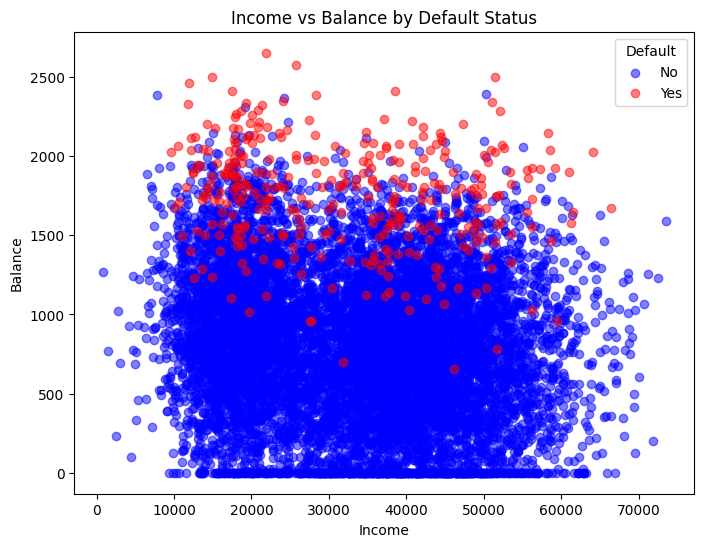

In [19]:
colors = {'No':'blue', 'Yes':'red'}

plt.figure(figsize=(8,6))

for d in default['default'].unique():
    subset = default[default['default'] == d]

    plt.scatter(
        subset['income'],
        subset['balance'],
        c=colors[d],
        label=d,
        alpha=0.5
    )

plt.xlabel('Income')
plt.ylabel('Balance')
plt.title('Income vs Balance by Default Status')
plt.legend(title='Default')
plt.show()

Interpretation: The scatterplot suggests that default status is more strongly associated with credit card balance than with income. Individuals who default tend to have higher balances, while income does not show a clear distinction between those who default and those who do not.

<Figure size 600x500 with 0 Axes>

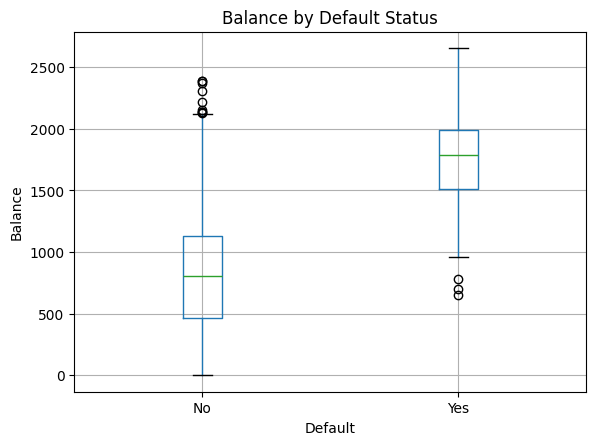

In [20]:
plt.figure(figsize=(6,5))

default.boxplot(column='balance', by='default')

plt.title('Balance by Default Status')
plt.suptitle('')
plt.xlabel('Default')
plt.ylabel('Balance')

plt.show()

Interpretation: The boxplot shows a clear relationship between credit card balance and default status. Customers who default tend to have substantially higher balances than customers who do not default.

<Figure size 600x500 with 0 Axes>

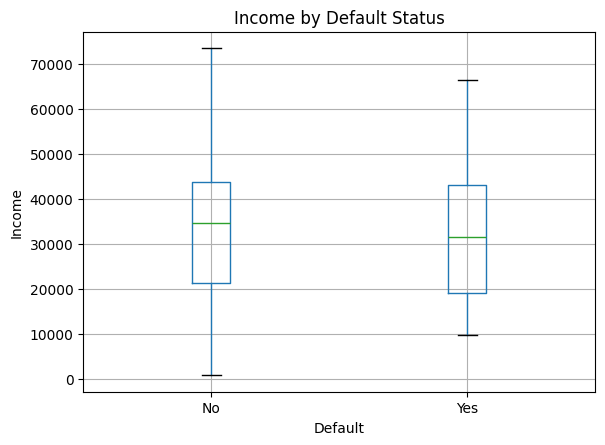

In [21]:
plt.figure(figsize=(6,5))

default.boxplot(column='income', by='default')

plt.title('Income by Default Status')
plt.suptitle('')
plt.xlabel('Default')
plt.ylabel('Income')

plt.show()

Interpretation: Income does not appear to be a strong predictor of default status in this dataset, since people who default and those who do not have similar income distributions.

<Figure size 600x500 with 0 Axes>

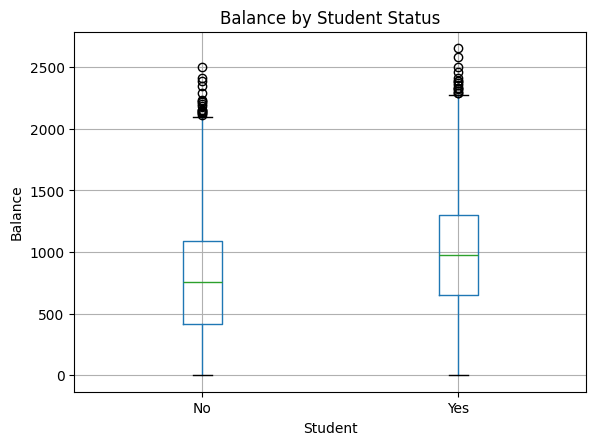

In [22]:
plt.figure(figsize=(6,5))

default.boxplot(column='balance', by='student')

plt.title('Balance by Student Status')
plt.suptitle('')
plt.xlabel('Student')
plt.ylabel('Balance')

plt.show()

Interpretation: Student status appears to be associated with higher credit card balances, although there is still substantial overlap between the two groups.

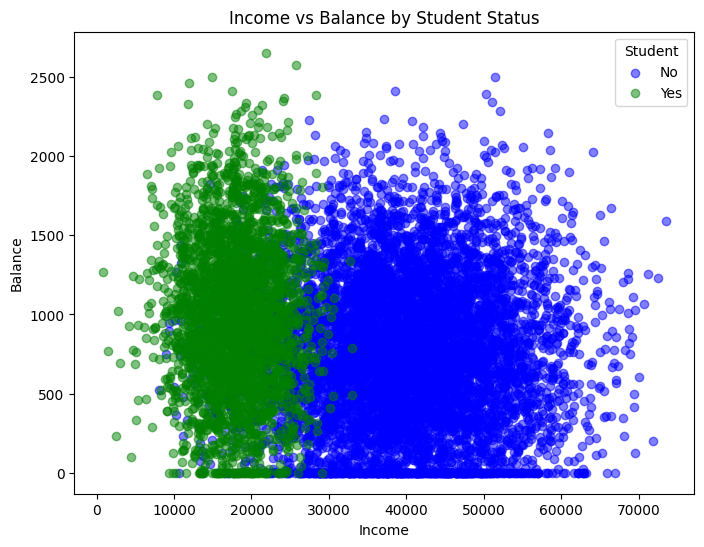

In [23]:
colors = {'No':'blue', 'Yes':'green'}

plt.figure(figsize=(8,6))

for s in default['student'].unique():
    subset = default[default['student'] == s]

    plt.scatter(
        subset['income'],
        subset['balance'],
        c=colors[s],
        label=s,
        alpha=0.5
    )

plt.xlabel('Income')
plt.ylabel('Balance')
plt.title('Income vs Balance by Student Status')
plt.legend(title='Student')
plt.show()

Interpretation: Student status is associated with lower income and somewhat higher credit card balances, but income itself does not appear to be a strong predictor of balance.